# Getting started with the NPPES history

This notebook shows how to read the **nppes-over-time** export and what a monthly history of the CMS National Plan and Provider Enumeration System (NPPES) can tell you that a single snapshot cannot. It runs against an export directory (`../export` by default, or `$NPPES_EXPORT`), reads the Parquet files lazily with DuckDB, and every query here finishes in a few seconds.

The export is a *slowly changing dimension, type 2* panel: one row per provider **version**, with the first and last snapshot dates on which CMS published that exact record. Six tables share the same version columns:

| Column | Meaning |
|---|---|
| `npi` | the 10-digit NPI, as text |
| `effective_date` | as-of date of the first monthly file that showed this version (inclusive) |
| `end_date` | as-of date of the first monthly file in which it was gone (exclusive); NULL while current |
| `close_reason` | `changed` (a new version followed), `absent` (the NPI left the file), NULL while current |

Everything else in a row is a CMS column, exactly as published, trimmed. The release README and `data_dictionary.csv` in the export describe every column.

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import nppes_nb as nb

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

con = nb.connect()          # views named provider, provider_taxonomy, ... over the Parquet export
import json
manifest = json.load(open(nb.export_dir() / "manifest.json"))
print("release:", manifest["release_id"], "| last snapshot:", manifest["last_as_of_date"])

release: e2-20261011-130309f4 | last snapshot: 2026-10-11


## 1. The snapshots

`snapshots.csv` lists every monthly CMS file in the build. The archive is monthly from April 2011 (May 2013 is missing); before that there are two to five files a year, so a change in those years is dated to the first file that showed it, which can be up to a year late.

197 snapshots from 2007-11-12 to 2026-10-11


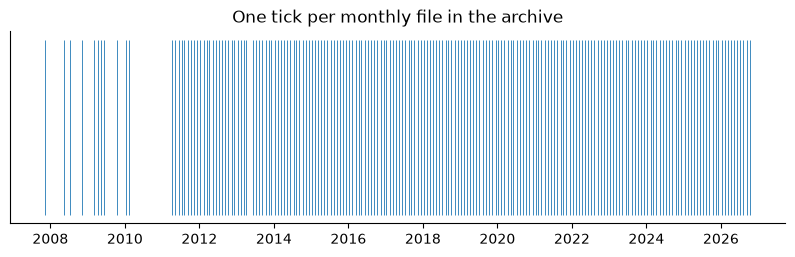

,snapshot_id,as_of_date,provider_rows,provider_new,provider_changed,provider_absent
194,20260809,2026-08-09,9726865,54979,165631,2
195,20260913,2026-09-13,9798758,71893,97317,0
196,20261011,2026-10-11,9852180,53422,1265159,0


In [2]:
snap = nb.snapshots()
print(len(snap), "snapshots from", snap.as_of_date.min().date(), "to", snap.as_of_date.max().date())
gaps = snap.as_of_date.diff().dt.days
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.vlines(snap.as_of_date, 0, 1, lw=0.6)
ax.set_yticks([]); ax.set_title("One tick per monthly file in the archive")
plt.show()
snap[["snapshot_id", "as_of_date", "provider_rows", "provider_new", "provider_changed", "provider_absent"]].tail(3)

## 2. One provider's history

Every version of one NPI, in order. Each row is a record CMS published; a new row appears whenever any of the 330 CMS columns changed.

In [3]:
con.sql("""
SELECT effective_date, end_date, close_reason, practice_address_1, practice_city, practice_state, last_update_date
FROM provider WHERE npi = '1205089596' ORDER BY effective_date
""").df()

,effective_date,end_date,close_reason,practice_address_1,practice_city,practice_state,last_update_date
0,2008-11-10,2009-03-08,changed,5940 W. Touhy Avenue,Niles,IL,2008-10-30
1,2009-03-08,2010-01-11,changed,5940 W. TOUHY AVENUE,NILES,IL,2008-10-30
2,2010-01-11,2011-04-11,changed,2121 WEST ARMY TRAIL ROAD,ADDISON,IL,2009-11-18
3,2011-04-11,2012-05-14,changed,7301 N LINCOLN AVE,LINCOLNWOOD,IL,2010-08-09
4,2012-05-14,2012-06-11,changed,2155 STONINGTON AVE.,HOFFMAN ESTATES,IL,2012-05-03
5,2012-06-11,2012-12-10,changed,2155 STONINGTON AVE.,HOFFMAN ESTATES,IL,2012-05-30
6,2012-12-10,2014-03-09,changed,2155 STONINGTON AVE.,HOFFMAN ESTATES,IL,2012-12-10
7,2014-03-09,2015-01-11,changed,2815 FORBS AVE,HOFFMAN ESTATES,IL,2014-03-06
8,2015-01-11,2017-12-10,changed,129 FAIRFIELD WAY,BLOOMINGDALE,IL,2014-12-29
9,2017-12-10,2018-07-08,changed,101 LIONS DR STE 113,BARRINGTON,IL,2017-11-29


Read it top to bottom: the home health agency moved six times, and CMS re-cased its address in March 2009 (a CMS-wide edit that re-versioned almost every provider). The `last_update_date` column is the date the provider's own update was processed, and it is usually two weeks before the snapshot that first shows the change.

## 3. The registry as of any date

Because the interval endpoints are snapshot dates, a filter on `effective_date` and `end_date` reproduces the monthly file exactly. The helper `nb.as_of(table, date)` writes that filter. Here we rebuild the provider count for one snapshot and check it against `snapshots.csv`.

In [4]:
d = "2019-01-13"
n = con.sql(f"SELECT count(*) AS providers FROM ({nb.as_of('provider', d)})").df().providers.item()
expected = snap.loc[snap.as_of_date == d, "provider_rows"].item()
print(f"as of {d}: {n:,} providers in the panel, {expected:,} rows in the CMS file")
assert n == expected

as of 2019-01-13: 5,844,727 providers in the panel, 5,844,727 rows in the CMS file


## 4. Growth of the registry

NPIs by entity type and by major provider family on each January snapshot. The taxonomy join uses slot 1 of `provider_taxonomy`, which is the primary taxonomy in canonical order.

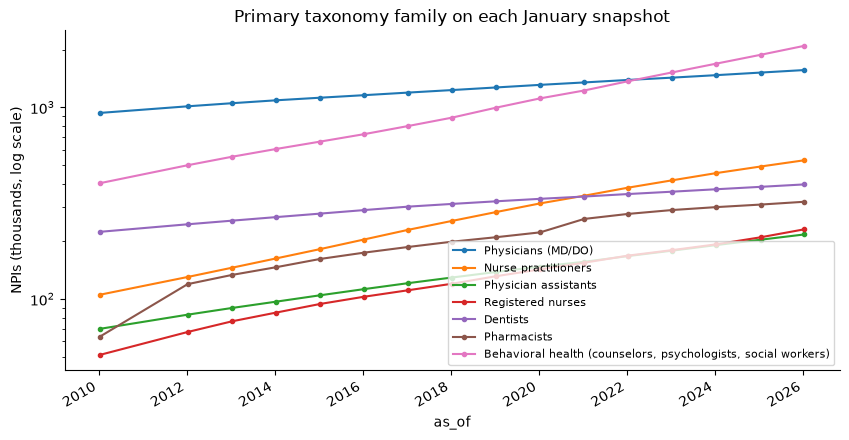

as_of,2010-01-11 00:00:00,2026-01-11 00:00:00
Individuals,"2,290,648","7,105,591"
Organizations,"731,318","1,885,061"
Physicians (MD/DO),"934,289","1,563,816"
Nurse practitioners,"105,182","529,186"
Physician assistants,"69,825","217,051"
Registered nurses,"51,063","230,864"
Dentists,"223,955","395,934"
Pharmacists,"63,581","321,409"
"Behavioral health (counselors, psychologists, social workers)","401,685","2,092,377"


In [5]:
families = {"Physicians (MD/DO)": "20%", "Nurse practitioners": "363L%", "Physician assistants": "363A%",
            "Registered nurses": "163W%", "Dentists": "12%", "Pharmacists": "1835%", "Behavioral health (counselors, psychologists, social workers)": "10%"}
dates = [d for d in nb.monthly_dates("2008-01-01") if d.month == 1]
rows = []
for d in dates:
    ds = d.date().isoformat()
    q = con.sql(f"""
        SELECT t.taxonomy_code, p.entity_type FROM ({nb.as_of('provider', ds, 'npi, effective_date, entity_type')}) p
        LEFT JOIN provider_taxonomy t ON t.npi = p.npi AND t.effective_date = p.effective_date AND t.slot = 1
    """).df()
    rec = {"as_of": d, "Individuals": (q.entity_type == "1").sum(), "Organizations": (q.entity_type == "2").sum()}
    for name, pat in families.items():
        rec[name] = q.taxonomy_code.fillna("").str.match(pat.replace("%", ".*")).sum()
    rows.append(rec)
growth = pd.DataFrame(rows).set_index("as_of")
ax = (growth[list(families)] / 1000).plot(logy=True, marker=".", figsize=(10, 5))
ax.set_ylabel("NPIs (thousands, log scale)"); ax.set_title("Primary taxonomy family on each January snapshot")
ax.legend(fontsize=8, loc="lower right"); plt.show()
(growth.iloc[[0, -1]].T).style.format("{:,.0f}")

Nurse practitioners quintupled between the January 2010 and January 2026 files, as did the behavioral health family, while physicians grew by about two thirds. That is why notebook 01 studies NPs.

## 5. Entry and exit

A snapshot gives `enumeration_date`, the day CMS issued the NPI. The history adds the month the provider first *appeared* in a public file and the month it left. From 2012 on, an NPI appears in the first monthly file after enumeration (median 16 days). Exits are rarer than you might think: a deactivated NPI stays in the file as a stub with only `npi` and `deactivation_date`, and `close_reason = 'absent'` is mostly a pre-2015 phenomenon when CMS dropped records outright.

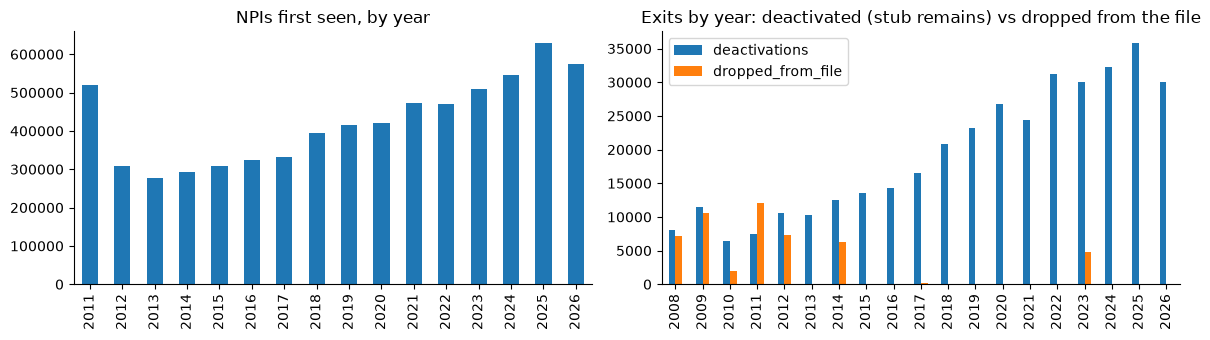

,npis_first_seen,median_days_after_enumeration,p90_days
year,,,
2011,519279,77.0,356.0
2012,308013,15.0,27.0
2013,276051,17.0,34.0
2014,293646,16.0,27.0
2015,307313,16.0,27.0
2016,324885,16.0,27.0
2017,332169,16.0,27.0
2018,395508,16.0,27.0
2019,414899,16.0,28.0


In [6]:
timing = con.sql("""
WITH f AS (SELECT npi, min(effective_date) AS first_seen, any_value(enumeration_date) AS enumerated FROM provider GROUP BY npi)
SELECT year(first_seen) AS year, count(*) AS npis_first_seen,
       quantile_cont(date_diff('day', enumerated, first_seen), 0.5) AS median_days_after_enumeration,
       quantile_cont(date_diff('day', enumerated, first_seen), 0.9) AS p90_days
FROM f WHERE first_seen >= DATE '2011-01-01' GROUP BY 1 ORDER BY 1
""").df().set_index("year")
exits = con.sql("""
SELECT year(d) AS year,
       count(*) FILTER (WHERE kind = 'deactivated') AS deactivations,
       count(*) FILTER (WHERE kind = 'absent') AS dropped_from_file
FROM (
  SELECT deactivation_date AS d, 'deactivated' AS kind FROM provider WHERE is_current AND deactivation_date IS NOT NULL
  UNION ALL
  SELECT end_date, 'absent' FROM provider WHERE close_reason = 'absent'
) WHERE d >= DATE '2008-01-01' GROUP BY 1 ORDER BY 1
""").df().set_index("year")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
timing.npis_first_seen.plot.bar(ax=axes[0], title="NPIs first seen, by year"); axes[0].set_xlabel("")
exits.plot.bar(ax=axes[1], title="Exits by year: deactivated (stub remains) vs dropped from the file"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
timing

## 6. Moves, and how precisely they are dated

A move is a version whose `practice_state` differs from the previous version of the same NPI. About one individual in nine has moved state since 2007. The second table is the point of a monthly archive: from 2012 on, the provider's own `last_update_date` is a median of two weeks before the snapshot that reveals the move, so the month of a move is known to within one file. An annual archive would place the same move anywhere in a twelve-month window and would miss a move that was reversed inside the year.

In [7]:
moves = con.sql("""
WITH v AS (
  SELECT npi, effective_date, last_update_date, practice_state,
         lag(practice_state) OVER (PARTITION BY npi ORDER BY effective_date) AS prev_state
  FROM provider WHERE entity_type = '1')
SELECT year(effective_date) AS year, count(*) AS state_moves,
       quantile_cont(date_diff('day', last_update_date, effective_date), 0.5) AS median_days_update_to_snapshot,
       quantile_cont(date_diff('day', last_update_date, effective_date), 0.9) AS p90_days
FROM v WHERE prev_state IS NOT NULL AND practice_state <> prev_state AND effective_date >= DATE '2011-01-01'
GROUP BY 1 ORDER BY 1
""").df().set_index("year")
movers = con.sql("""
WITH v AS (SELECT npi, practice_state, lag(practice_state) OVER (PARTITION BY npi ORDER BY effective_date) AS prev
           FROM provider WHERE entity_type = '1')
SELECT count(DISTINCT npi) FILTER (WHERE prev IS NOT NULL AND prev <> practice_state) AS movers, count(DISTINCT npi) AS individuals FROM v
""").df()
print(f"{movers.movers.item():,} of {movers.individuals.item():,} individuals have changed practice state at least once")
moves

861,862 of 7,774,362 individuals have changed practice state at least once


,state_moves,median_days_update_to_snapshot,p90_days
year,,,
2011,68540,33.0,305.0
2012,45509,14.0,27.0
2013,48898,16.0,32.0
2014,48231,14.0,27.0
2015,50725,13.0,26.0
2016,55082,13.0,26.0
2017,50387,13.0,26.0
2018,56051,13.0,26.0
2019,67664,13.0,28.0


## 7. Which versions are noise

A new version is created when *any* column changes, so the history also records CMS housekeeping. Three snapshots re-versioned almost every provider: May 2008 and March 2009 (CMS reformatting, including upper-casing every name and address) and July 2018 (new columns). Cosmetic edits such as `ST. LOUIS` to `ST LOUIS` also create versions. The cell below classifies every `changed` version by what changed, so you can see how much of the churn is the kind you care about.

In [8]:
churn = con.sql("""
WITH v AS (
  SELECT npi, effective_date, practice_state, practice_postal_code, practice_address_1, last_name, org_name,
         lag(practice_state) OVER w AS p_state, lag(practice_postal_code) OVER w AS p_zip,
         lag(practice_address_1) OVER w AS p_addr, lag(last_name) OVER w AS p_last, lag(org_name) OVER w AS p_org,
         lag(effective_date) OVER w AS p_eff
  FROM provider WINDOW w AS (PARTITION BY npi ORDER BY effective_date))
SELECT year(effective_date) AS year, count(*) AS versions,
  round(100.0 * count(*) FILTER (WHERE practice_state IS DISTINCT FROM p_state) / count(*), 1) AS pct_state_changed,
  round(100.0 * count(*) FILTER (WHERE practice_state IS NOT DISTINCT FROM p_state AND left(practice_postal_code, 5) IS DISTINCT FROM left(p_zip, 5)) / count(*), 1) AS pct_zip_changed_same_state,
  round(100.0 * count(*) FILTER (WHERE upper(practice_address_1) = upper(p_addr) AND practice_address_1 <> p_addr) / count(*), 1) AS pct_address_case_only,
  round(100.0 * count(*) FILTER (WHERE regexp_replace(upper(practice_address_1), '[^A-Z0-9]', '', 'g') = regexp_replace(upper(p_addr), '[^A-Z0-9]', '', 'g') AND practice_address_1 <> p_addr) / count(*), 1) AS pct_address_punct_or_case_only
FROM v WHERE p_eff IS NOT NULL GROUP BY 1 ORDER BY 1
""").df().set_index("year")
churn

,versions,pct_state_changed,pct_zip_changed_same_state,pct_address_case_only,pct_address_punct_or_case_only
year,,,,,
2008,5227814,0.5,1.3,0.0,0.1
2009,2943182,0.9,1.9,89.9,89.9
2010,128742,6.5,15.9,0.0,0.3
2011,1336088,5.2,10.6,0.0,0.2
2012,492372,17.9,19.1,0.0,0.3
2013,448641,13.3,21.4,0.0,0.2
2014,421450,14.4,22.1,0.0,0.2
2015,431353,15.1,22.6,0.0,0.2
2016,445005,15.7,23.2,0.0,0.2


## 8. Monthly versus annual: what a yearly archive hides

NBER's earlier cumulative collection stacked one file a year and kept a record only when something changed. For most providers that is enough. For the ones who move, the monthly panel shows what the annual view collapses. The next cell finds a provider with three or more practice-state changes inside one calendar year and prints both views.

In [9]:
busy = con.sql("""
WITH v AS (SELECT npi, effective_date, practice_state, lag(practice_state) OVER (PARTITION BY npi ORDER BY effective_date) AS prev
           FROM provider WHERE entity_type = '1' AND effective_date >= DATE '2015-01-01')
SELECT npi, year(effective_date) AS year, count(*) AS moves FROM v
WHERE prev IS NOT NULL AND practice_state <> prev GROUP BY 1, 2 HAVING count(*) >= 3 ORDER BY moves DESC, npi LIMIT 1
""").df()
npi, year = busy.npi.item(), int(busy.year.item())
hist = con.sql(f"""
SELECT effective_date, end_date, practice_city, practice_state FROM provider
WHERE npi = '{npi}' AND year(effective_date) BETWEEN {year - 1} AND {year + 1} ORDER BY effective_date
""").df()
print(f"NPI {npi} in {year}: monthly view")
display(hist)
annual = hist[hist.effective_date.dt.month == 1] if (hist.effective_date.dt.month == 1).any() else hist.iloc[[0, -1]]
print("what a once-a-year archive (January files) would show:")
display(annual[["effective_date", "practice_city", "practice_state"]])

NPI 1104053099 in 2016: monthly view


,effective_date,end_date,practice_city,practice_state
0,2015-05-10,2015-11-08,YPSILANTI,MI
1,2015-11-08,2016-04-10,NEW YORK,NY
2,2016-04-10,2016-05-08,YPSILANTI,MI
3,2016-05-08,2016-06-12,NEW YORK,NY
4,2016-06-12,2016-07-10,YPSILANTI,MI
5,2016-07-10,2017-06-11,NEW YORK,NY
6,2017-06-11,2021-07-11,YPSILANTI,MI


what a once-a-year archive (January files) would show:


,effective_date,practice_city,practice_state
0,2015-05-10,YPSILANTI,MI
6,2017-06-11,YPSILANTI,MI


## 9. Reading the export from other tools

The helper functions used above are short and live in `nppes_nb.py` next to this notebook. The two you will reuse are `nb.connect()` and `nb.as_of()`. For R, Stata and plain DuckDB, the release `README.md` in the export directory has recipes; the one query to remember is the as-of filter:

```sql
SELECT * FROM read_parquet('parquet/provider/*/*.parquet', hive_partitioning = true)
WHERE effective_date <= DATE '2019-01-13' AND (end_date IS NULL OR end_date > DATE '2019-01-13')
```

Notebook 01 uses all of this to study a policy question: whether state laws that free nurse practitioners from physician oversight change where NPs work.